# Creating the ARIMA baseline models

In [2]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np

sys.path.append('../')

from model_recurrent import Model

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-09-26 14:51:07,597	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-09-26 14:51:09,124	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [3]:
df = pd.read_csv("../full_data.csv")

# Best non-recurrent

Auto SARIMA(0, 0, 0)(0, 0, 0, 52) NRMSE: 4.0000
Auto SARIMAX(0, 0, 0)(0, 0, 0, 52) NRMSE: 3.7421


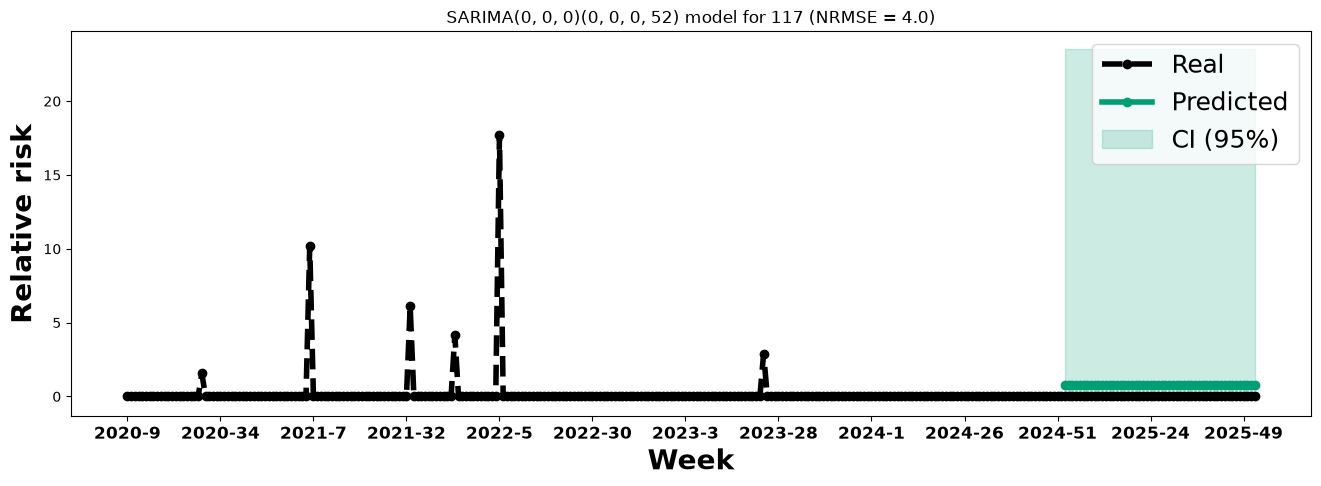

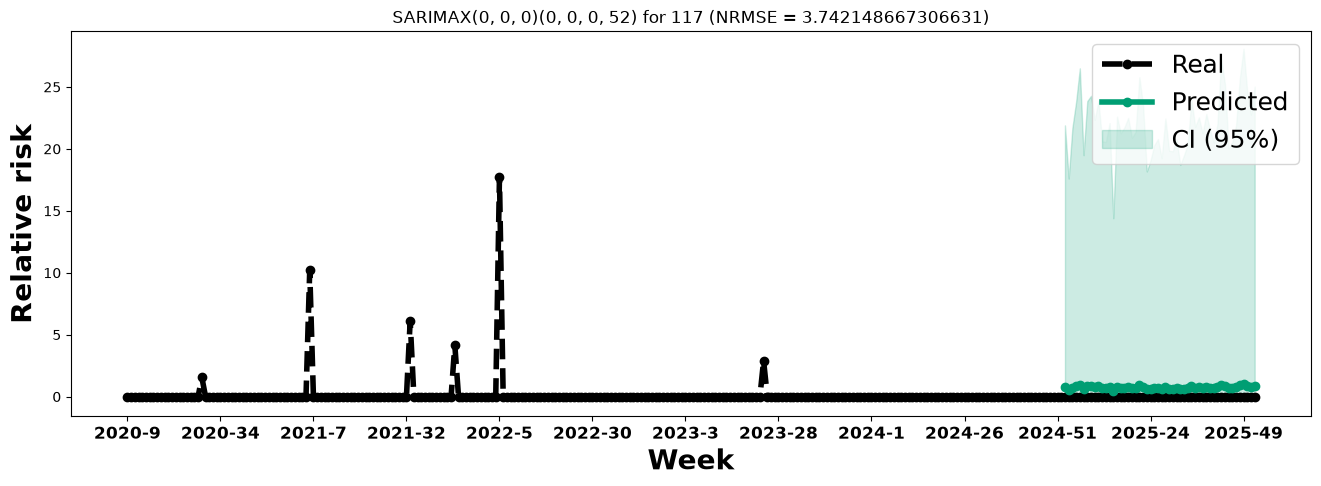

In [9]:
model0 = Model(df, "117")
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()

features = X_test.drop(columns = ["rr_lag_1", "rr_lag_2", "rr_lag_3", "rr_lag_4"])
features = features.astype(float)
model0.arima_forecast_plot(y_combined, y_test, epsilon)
model0.arima_forecast_plot(y_combined, y_test, epsilon, exog = features)

Auto SARIMA(0, 1, 1)(1, 0, 0, 52) NRMSE: 0.2691
Auto SARIMAX(0, 1, 1)(1, 0, 0, 52) NRMSE: 0.2812


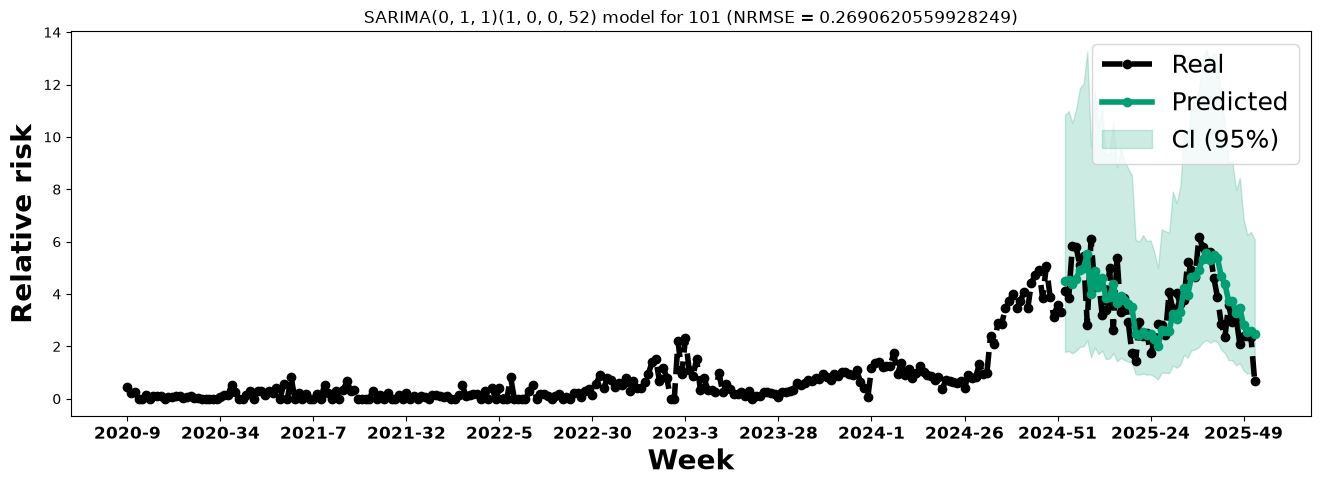

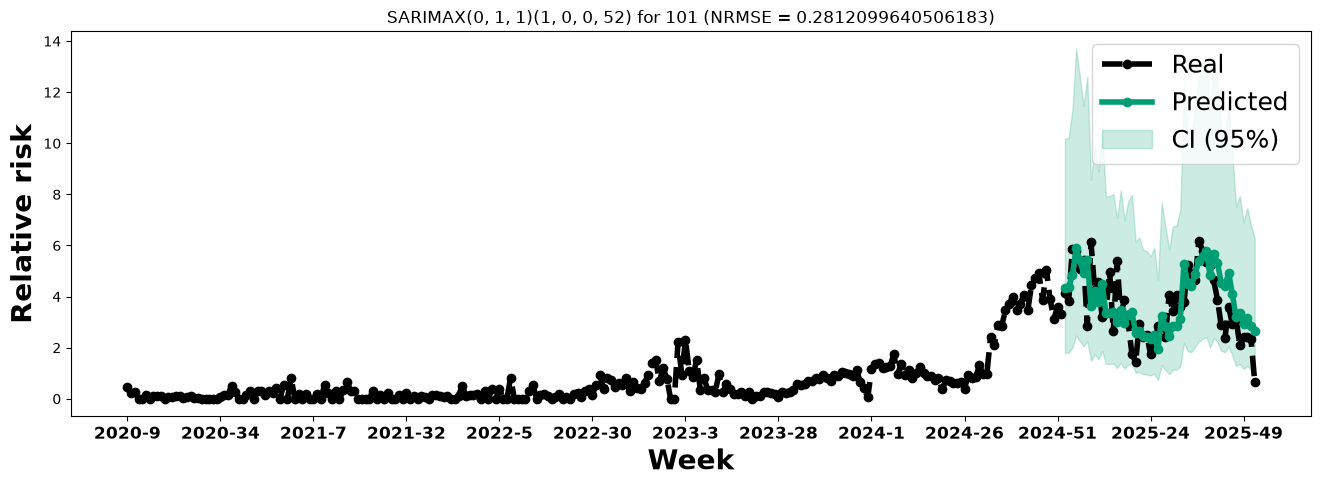

In [10]:
model0 = Model(df, "101")
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()

features = X_test.drop(columns = ["rr_lag_1", "rr_lag_2", "rr_lag_3", "rr_lag_4"])
features = features.astype(float)
model0.arima_forecast_plot(y_combined, y_test, epsilon)
model0.arima_forecast_plot(y_combined, y_test, epsilon, exog = features)

Auto SARIMA(0, 1, 2)(0, 0, 2, 52) NRMSE: 0.5411
Auto SARIMAX(2, 1, 3)(2, 0, 0, 52) NRMSE: 0.5333


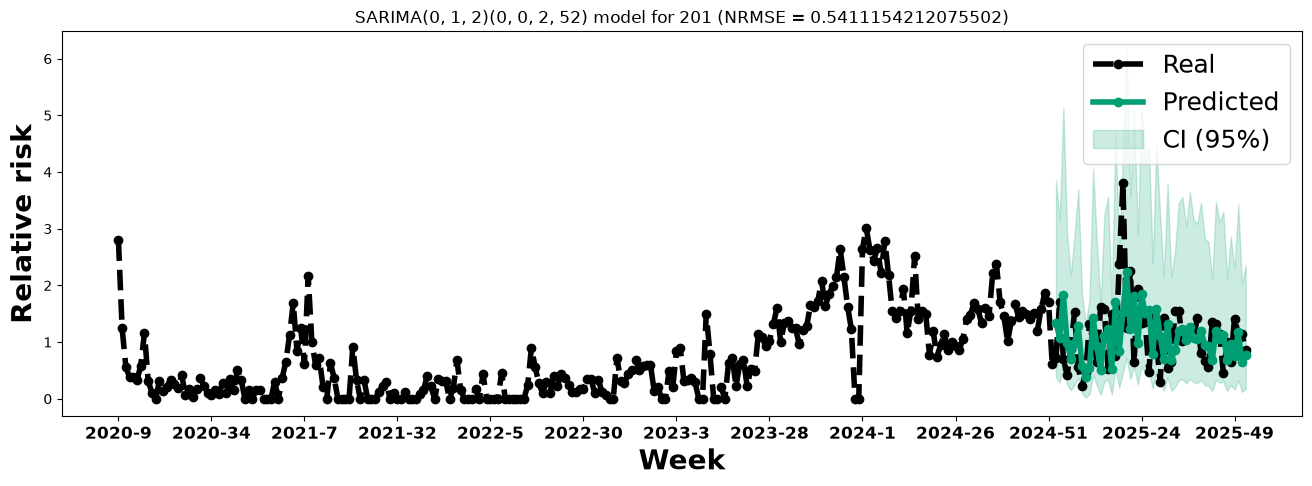

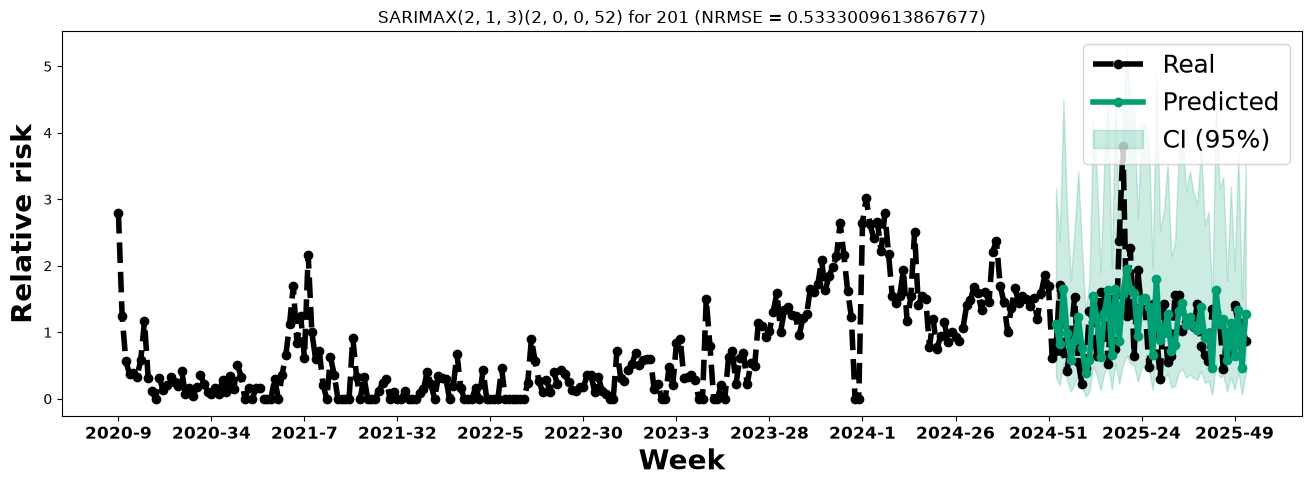

In [4]:
model0 = Model(df, "201")
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()

features = X_test.drop(columns = ["rr_lag_1", "rr_lag_2", "rr_lag_3", "rr_lag_4"])
features = features.astype(float)
model0.arima_forecast_plot(y_combined, y_test, epsilon)
model0.arima_forecast_plot(y_combined, y_test, epsilon, exog = features)

Auto SARIMA(0, 1, 1)(0, 0, 0, 52) NRMSE: 0.5913
Auto SARIMAX(0, 1, 1)(0, 0, 0, 52) NRMSE: 0.5835


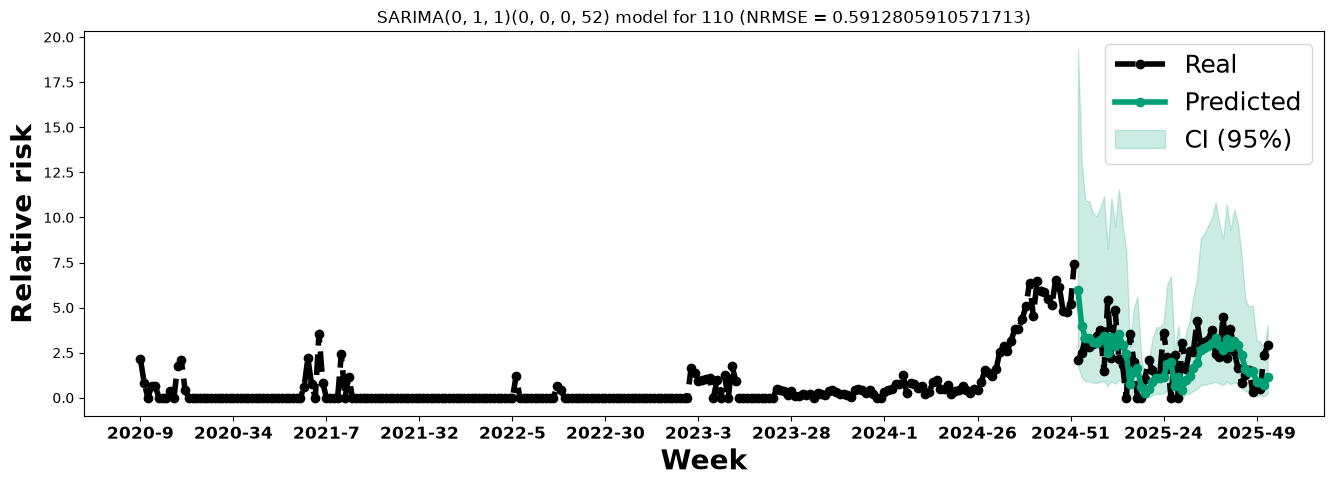

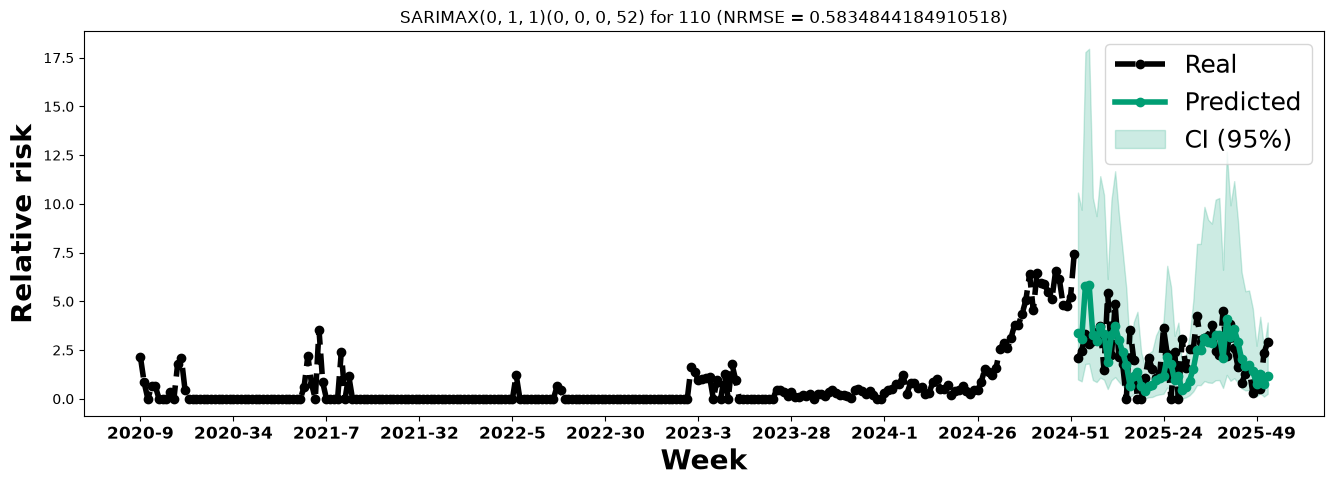

In [5]:
model0 = Model(df, "110")
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()

features = X_test.drop(columns = ["rr_lag_1", "rr_lag_2", "rr_lag_3", "rr_lag_4"])
features = features.astype(float)
model0.arima_forecast_plot(y_combined, y_test, epsilon)
model0.arima_forecast_plot(y_combined, y_test, epsilon, exog = features)

# NRMSE comparison with non-recurrent models

C:\Windows\Temp\ipykernel_3028\3771248113.py:110: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")


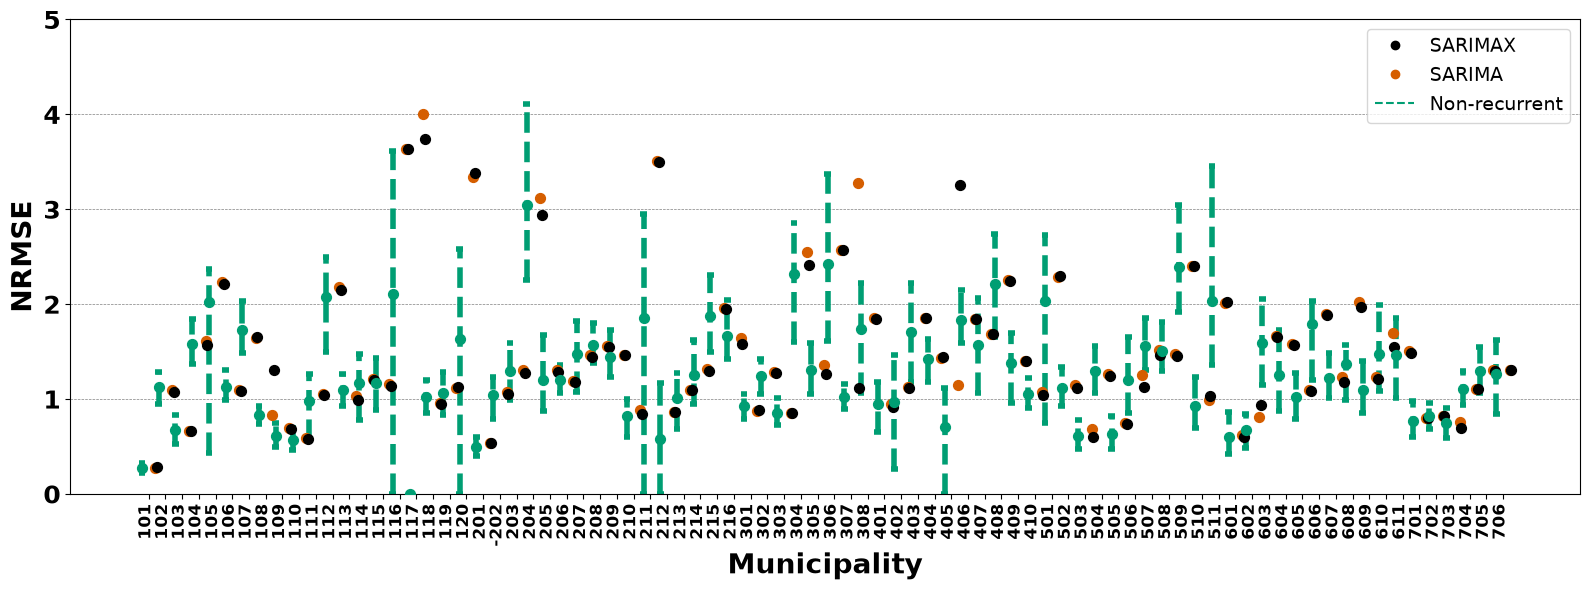

In [8]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms
      
non_recurrent = pd.read_csv(
        f"../data/metrics/best_non_recurrent_confint_test.csv"
    ) 

recurrent = pd.read_csv(
        f"../data/metrics/nrmse_arima_test.csv"
    )

x = np.arange(len(non_recurrent))

fig, ax = plt.subplots(figsize=(16, 6))

cap_width = 0.2

for i, row in non_recurrent.iterrows():
    # Plotting the individual model NRMSE results

    mean_col = row["best_mean_model"]
    lower_col = mean_col.replace("mean_", "lower_")
    upper_col = mean_col.replace("mean_", "upper_")
    
    ax.vlines(
        # Confidence intervals
        x[i],
        row[lower_col],
        row[upper_col],
        color="#009E73",
        linewidth=4,
        linestyles="--"
    )

    # Extremes of the confidence intervals
    ax.hlines(
        row[lower_col],
        x[i]-cap_width,
        x[i]+cap_width,
        color="#009E73",
        linestyles="--",
        linewidth=4
    )

    ax.hlines(
        row[upper_col],
        x[i]-cap_width,
        x[i]+cap_width,
        color="#009E73",
        linestyles="--",
        linewidth=4
    )

    ax.scatter(
        # Plotting the mean as a point
        x[i],
        row[mean_col],
        color="#009E73",
        marker="o",
        s=50,
        zorder=4
    )

for i, row in recurrent.iterrows():
    # Plotting the global model NRMSE results
    x_full = x[i] + 0.8

    ax.scatter(
    # Plotting the individual model NRSME results
        x_full,
        row["sarima"],
        color="#D55E00",
        s=50,
        zorder=3
    )

for i, row in recurrent.iterrows():
    # Plotting the global model NRMSE results

    x_full = x[i] + 0.9

    ax.scatter(
    # Plotting the individual model NRSME results
        x_full,
        row["sarimax"],
        color="#000000",
        s=50,
        zorder=3
    )

# Adding and transforming municipality labels in the x-axis so that visualization is more orderly and readable
ax.set_xticks(x + 0.4)
ax.set_xticklabels(recurrent["canton"], rotation=90, ha="right", fontsize = 12, fontweight="bold")
dx = 4 / 72.0  
offset = transforms.ScaledTranslation(dx, 0, fig.dpi_scale_trans)
for label in ax.get_xticklabels():
    label.set_transform(label.get_transform() + offset)

style_handles = [
    # Adding the legend
    Line2D([0], [0], marker="o", color="#000000", linestyle="None", label="SARIMAX"),
    Line2D([0], [0], marker="o", color="#D55E00", linestyle="None", label="SARIMA"),    
    Line2D([0], [0], linestyle="dashed", color="#009E73", label="Non-recurrent"),
]
    
ax.set_ylabel("NRMSE", fontsize = 20, fontweight="bold")
ax.set_xlabel("Municipality", fontsize = 20, fontweight="bold")
ax.set_ylim([0, 5])
ax.set_yticklabels(range(0, 6), fontsize = 18, fontweight="bold")
ax.legend(handles=style_handles, fontsize=14, loc="upper right")

plt.grid(axis='y', color = 'gray', linestyle = '--', linewidth = 0.5)
plt.tight_layout()
plt.show()